# 1 Biomedical Applications of Wavelet Transforms

## 1.3 Real-World Dataset: PhysioNet

### 1.3.2 Accessing PhysioNet Data

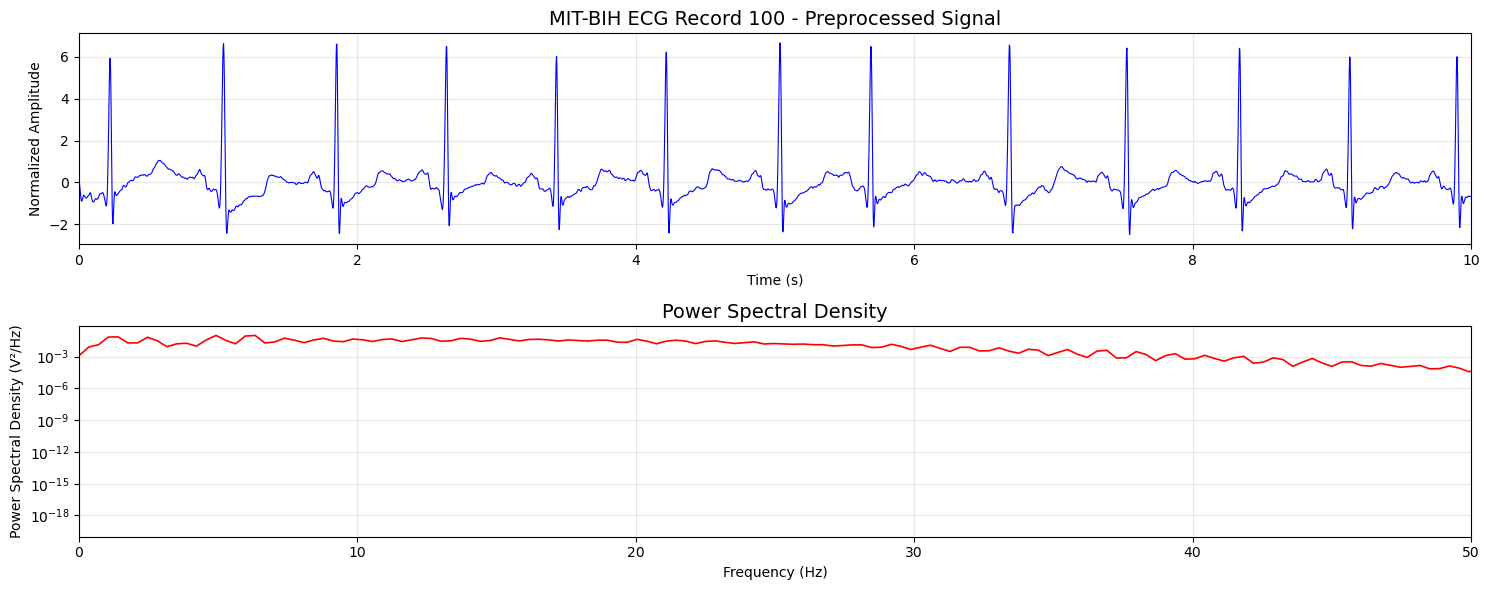

In [ ]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import warnings
warnings.filterwarnings('ignore')

def load_and_preprocess_ecg(record_name, database='mitdb', duration=10):
    """
    Load and preprocess ECG data from PhysioNet
    
    Parameters:
    record_name (str): Record identifier
    database (str): Database name
    duration (int): Duration in seconds to load
    
    Returns:
    tuple: (ecg_signal, fs, time_vector)
    """
    try:
        # Load ECG record from PhysioNet
        record = wfdb.rdrecord(record_name, pn_dir=database)
        fs = record.fs  # Sampling frequency
        
        # Extract signal and limit duration
        ecg_signal = record.p_signal[:int(duration * fs), 0]
        
        # Preprocessing steps
        # 1. Remove baseline wander using high-pass filter
        sos = signal.butter(4, 0.5, btype='highpass', fs=fs, output='sos')
        ecg_filtered = signal.sosfilt(sos, ecg_signal)
        
        # 2. Remove high-frequency noise using low-pass filter  
        sos_lp = signal.butter(4, 40, btype='lowpass', fs=fs, output='sos')
        ecg_clean = signal.sosfilt(sos_lp, ecg_filtered)
        
        # 3. Normalize signal
        ecg_normalized = (ecg_clean - np.mean(ecg_clean)) / np.std(ecg_clean)
        
        # Create time vector
        time = np.arange(len(ecg_normalized)) / fs
        
        return ecg_normalized, fs, time
        
    except Exception as e:
        print(f"Error loading data: {e}")
        return None, None, None

# Load and visualize ECG data
ecg_signal, fs, time = load_and_preprocess_ecg('100', duration=10)

if ecg_signal is not None:
    plt.figure(figsize=(15, 6))
    plt.subplot(2, 1, 1)
    plt.plot(time, ecg_signal, 'b-', linewidth=0.8)
    plt.title('MIT-BIH ECG Record 100 - Preprocessed Signal', fontsize=14)
    plt.xlabel('Time (s)')
    plt.ylabel('Normalized Amplitude')
    plt.grid(True, alpha=0.3)
    plt.xlim(0, 10)
    
    # Power spectral density
    plt.subplot(2, 1, 2)
    freqs, psd = signal.welch(ecg_signal, fs, nperseg=1024)
    plt.semilogy(freqs, psd, 'r-', linewidth=1.2)
    plt.title('Power Spectral Density', fontsize=14)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Power Spectral Density (V²/Hz)')
    plt.grid(True, alpha=0.3)
    plt.xlim(0, 50)
    
    plt.tight_layout()
    plt.savefig('./output/ecg_preprocessed.png', dpi=300)
    plt.show()

### 1.3.3 Downloading PhysionNet Data

Using cached file: data\chb01_01.edf


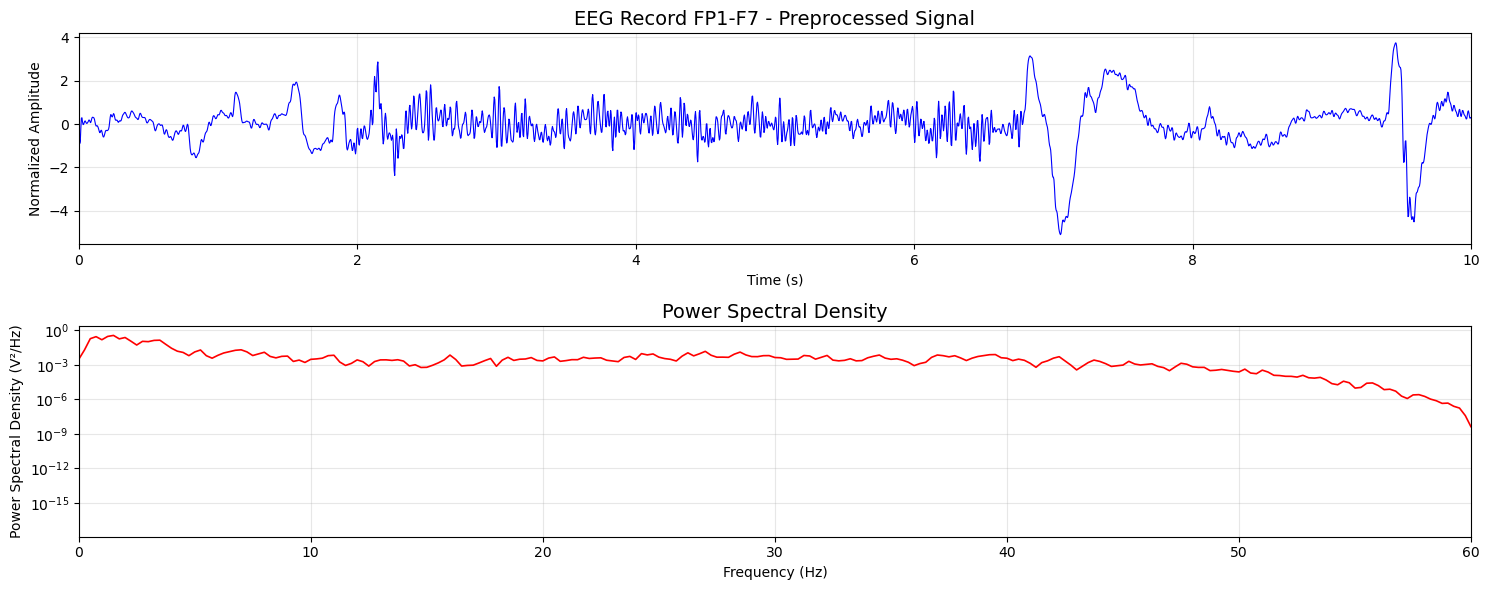

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import mne
import requests, os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

def load_and_preprocess_eeg(record_url, duration=10, bandpass=(0.5, 50), powerline=60, channel_index=0, cache_dir="data"):
    """
    Load and preprocess EEG data from PhysioNet EDF
    
    Parameters:
    record_url (str): Full URL to the EDF file (PhysioNet link)
    duration (int): Duration in seconds to load
    bandpass (tuple): Bandpass filter (low, high) in Hz
    powerline (int): Powerline frequency (50 or 60 Hz)
    channel_index (int): Which EEG channel to load
    cache_dir (str): Local folder to cache EDF
    
    Returns:
    tuple: (eeg_signal, fs, time_vector, channel_name)
    """
    try:
        os.makedirs(cache_dir, exist_ok=True)
        filename = record_url.split("/")[-1]
        filepath = Path(cache_dir) / filename

        # Download once and cache
        if not filepath.exists():
            print(f"Downloading {filename}...")
            r = requests.get(record_url, stream=True)
            r.raise_for_status()
            with open(filepath, "wb") as f:
                for chunk in r.iter_content(chunk_size=8192):
                    f.write(chunk)
            print(f"Saved to {filepath}")
        else:
            print(f"Using cached file: {filepath}")

        # Load EDF with MNE
        raw = mne.io.read_raw_edf(filepath, preload=True, verbose=False)
        fs = int(raw.info['sfreq'])  # sampling frequency
        channels = raw.ch_names

        if channel_index >= len(channels):
            raise ValueError(f"Invalid channel_index {channel_index}, file has {len(channels)} channels.")

        ch_name = channels[channel_index]
        data, _ = raw[channel_index, :int(duration * fs)]
        eeg_signal = data[0]  # shape (n_samples,)

        # --- Preprocessing ---
        # Bandpass filter
        sos = signal.butter(4, bandpass, btype='bandpass', fs=fs, output='sos')
        eeg_filtered = signal.sosfilt(sos, eeg_signal)

        # Notch filter for powerline noise
        b_notch, a_notch = signal.iirnotch(powerline, 30, fs)
        eeg_clean = signal.filtfilt(b_notch, a_notch, eeg_filtered)

        # Normalize
        eeg_normalized = (eeg_clean - np.mean(eeg_clean)) / np.std(eeg_clean)

        # Time vector
        time = np.arange(len(eeg_normalized)) / fs

        return eeg_normalized, fs, time, ch_name

    except Exception as e:
        print(f"Error loading EEG: {e}")
        return None, None, None, None

# Example EEG file from CHB-MIT PhysioNet
url = "https://physionet.org/files/chbmit/1.0.0/chb01/chb01_01.edf"

eeg_signal, fs, time, ch_name = load_and_preprocess_eeg(url, duration=10, channel_index=0)

if eeg_signal is not None:
    plt.figure(figsize=(15, 6))
    plt.subplot(2, 1, 1)
    plt.plot(time, eeg_signal, 'b-', linewidth=0.8)
    plt.title(f'EEG Record {ch_name} - Preprocessed Signal', fontsize=14)
    plt.xlabel('Time (s)')
    plt.ylabel('Normalized Amplitude')
    plt.grid(True, alpha=0.3)
    plt.xlim(0, 10)

    # Power spectral density
    plt.subplot(2, 1, 2)
    freqs, psd = signal.welch(eeg_signal, fs, nperseg=1024)
    plt.semilogy(freqs, psd, 'r-', linewidth=1.2)
    plt.title('Power Spectral Density', fontsize=14)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Power Spectral Density (V²/Hz)')
    plt.grid(True, alpha=0.3)
    plt.xlim(0, 60)

    plt.tight_layout()
    plt.savefig('./output/eeg_preprocessed.png', dpi=300)
    plt.show()

## 1.4 Multi-Scale Decomposition with PyWavelets

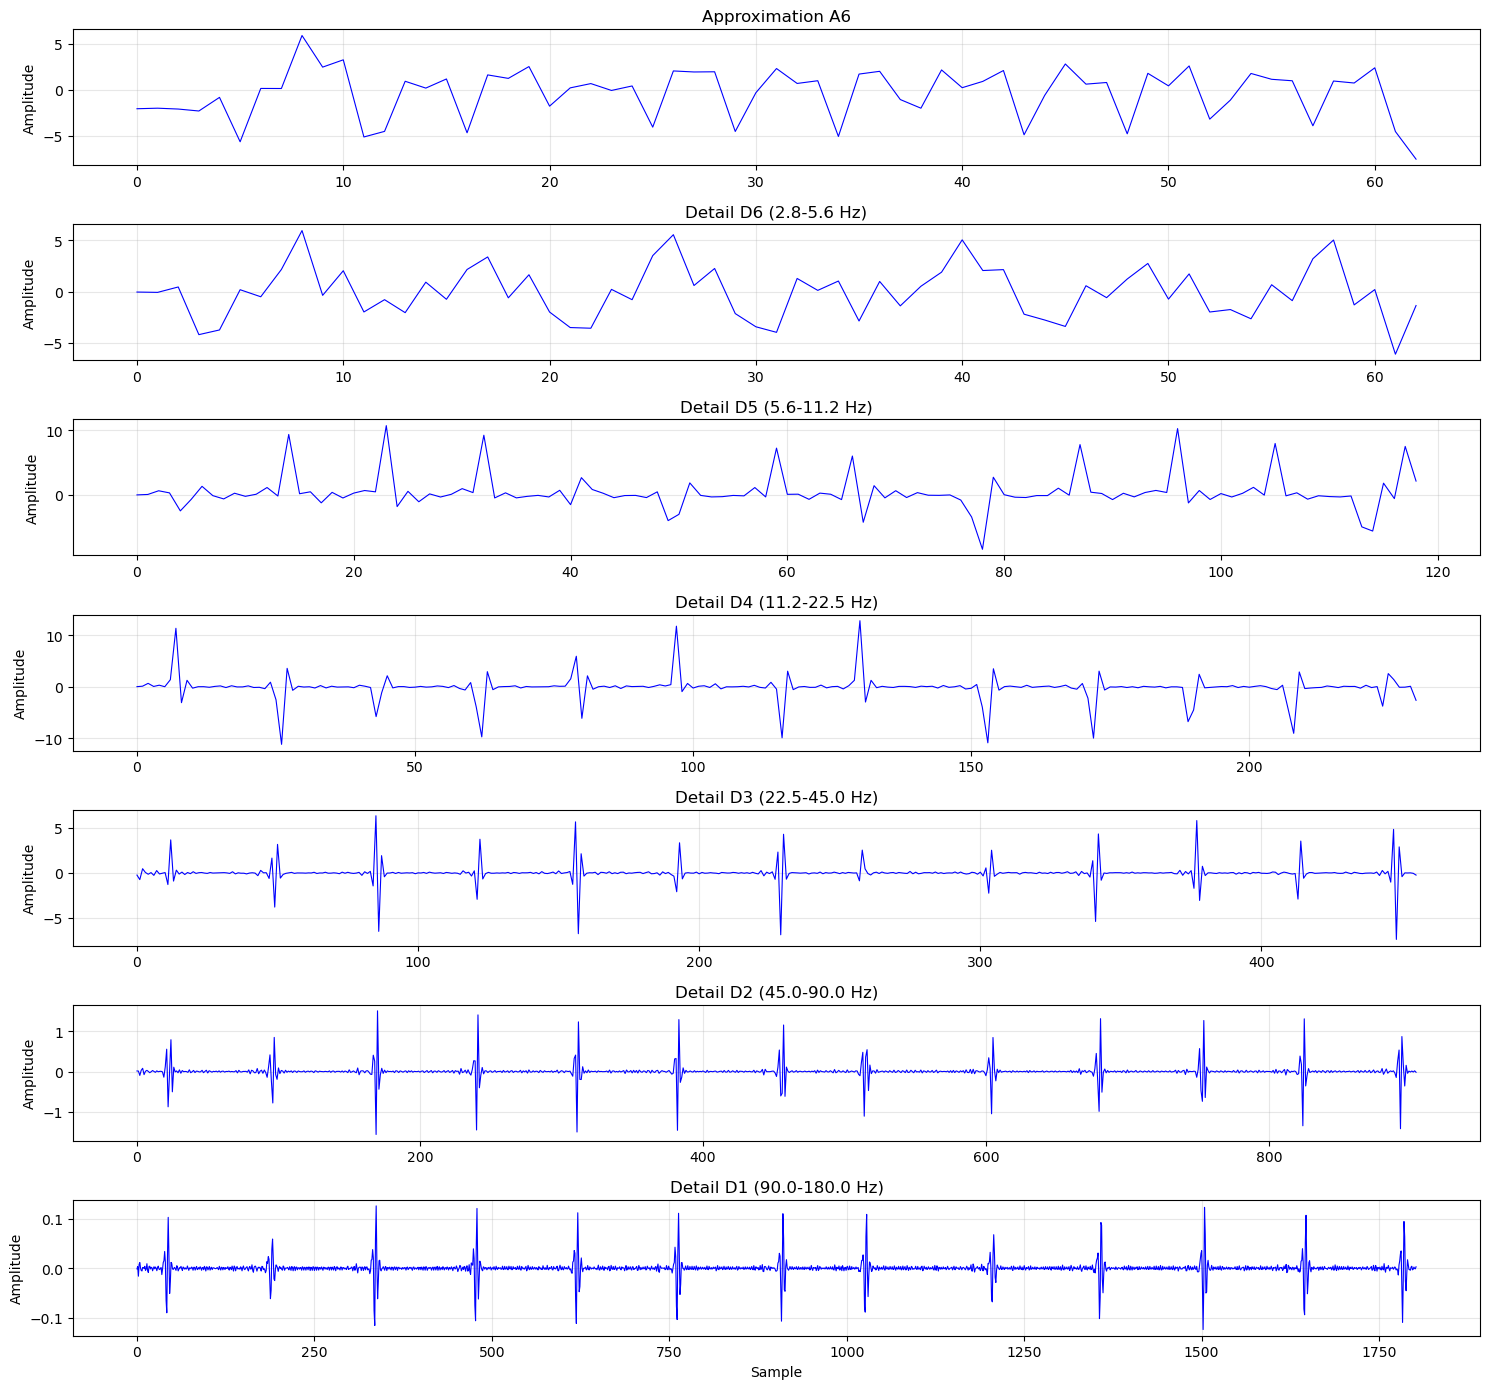

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

def comprehensive_wavelet_analysis(signal, wavelet='db4', levels=6, fs=360):
    """
    Perform comprehensive wavelet decomposition and analysis
    
    Parameters:
    signal (array): Input signal
    wavelet (str): Wavelet type
    levels (int): Decomposition levels
    fs (int): Sampling frequency
    
    Returns:
    dict: Analysis results including coefficients, energies, and frequency bands
    """
    # Normalize signal
    signal_norm = signal / np.std(signal)
    
    # Wavelet decomposition
    coeffs = pywt.wavedec(signal_norm, wavelet, level=levels)
    
    # Calculate frequency bands for each level
    freq_bands = []
    for i in range(levels + 1):
        if i == 0:
            # Approximation coefficients
            f_low = 0
            f_high = fs / (2 ** (levels + 1))
        else:
            # Detail coefficients
            f_low = fs / (2 ** (levels - i + 2))
            f_high = fs / (2 ** (levels - i + 1))
        freq_bands.append((f_low, f_high))
    
    # Calculate energy and statistics for each level
    energies = []
    entropies = []
    for c in coeffs:
        energy = np.sum(c**2) / len(c)
        energies.append(energy)
        # Shannon entropy as complexity measure
        c_abs = np.abs(c)
        if np.sum(c_abs) > 0:
            c_prob = c_abs / np.sum(c_abs)
            ent = entropy(c_prob)
        else:
            ent = 0
        entropies.append(ent)
    
    # Visualization
    plt.figure(figsize=(15, 2 * (levels + 1)))
    for i, c in enumerate(coeffs):
        plt.subplot(levels + 1, 1, i + 1)
        plt.plot(c, 'b-', linewidth=0.8)
        title = f'Approximation A{levels}' if i == 0 else f'Detail D{levels - i + 1} ({freq_bands[i][0]:.1f}-{freq_bands[i][1]:.1f} Hz)'
        plt.title(title, fontsize=12)
        plt.grid(True, alpha=0.3)
        plt.ylabel('Amplitude')
        if i == levels:
            plt.xlabel('Sample')
    plt.tight_layout()
    plt.savefig('./output/ecg_wavelet_decomposition.png', dpi=300)
    plt.show()
    
    return {
        'coeffs': coeffs,
        'energies': energies,
        'entropies': entropies,
        'freq_bands': freq_bands
    }

# Example usage
if ecg_signal is not None:
    analysis_results = comprehensive_wavelet_analysis(ecg_signal, wavelet='db4', levels=6, fs=fs)

## 1.5 Anomaly Detection in ECG Signals

### 1.5.1 Advanced Thresholding and Anomaly Localization

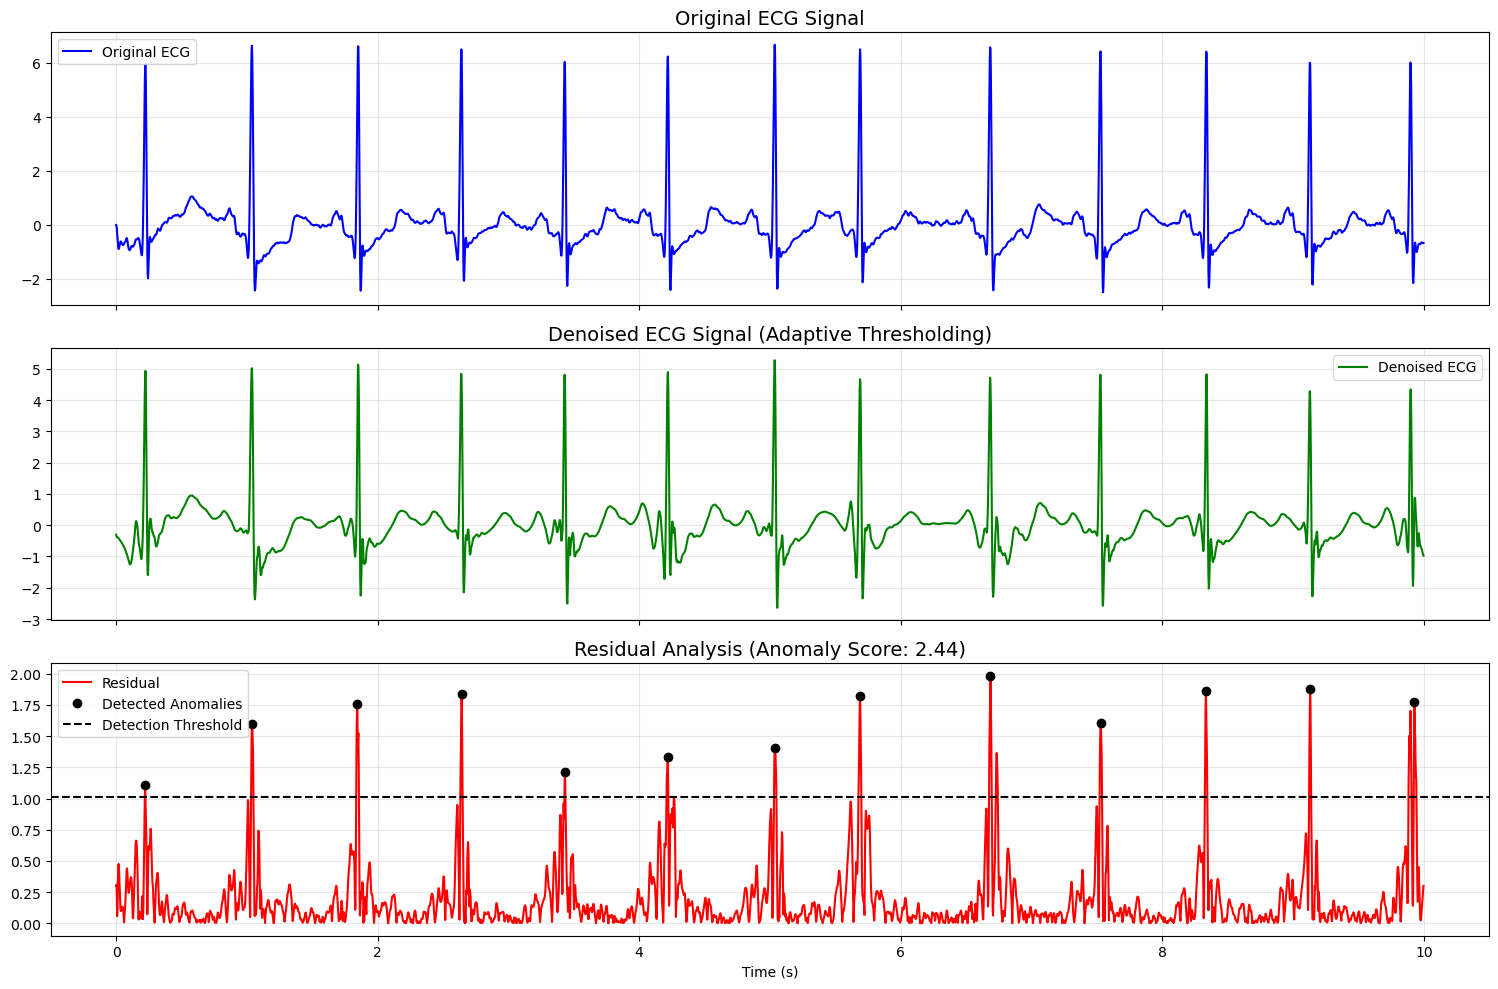

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation as mad
from scipy.signal import find_peaks

def advanced_thresholding(coeffs, method='adaptive', sigma_factor=1.5):
    """
    Apply advanced thresholding to wavelet coefficients
    
    Parameters:
    coeffs (list): Wavelet decomposition coefficients
    method (str): Thresholding method ('universal', 'minimax', 'adaptive')
    sigma_factor (float): Adjustment factor for threshold sensitivity
    
    Returns:
    list: Thresholded coefficients
    """
    thresholded_coeffs = [coeffs[0]]  # Preserve approximation
    
    for level, detail in enumerate(coeffs[1:], 1):
        n = len(detail)
        sigma = mad(detail) / 0.6745  # Robust noise estimation
        
        if method == 'universal':
            thresh = sigma * np.sqrt(2 * np.log(n))
        elif method == 'minimax':
            thresh = sigma * (0.3936 + 0.1829 * np.log2(n))
        elif method == 'adaptive':
            # Level-dependent threshold
            thresh = sigma * np.sqrt(2 * np.log(n / np.log(level + 1)))
        else:
            raise ValueError("Invalid thresholding method")
        
        thresh *= sigma_factor
        thresholded_coeffs.append(pywt.threshold(detail, thresh, mode='soft'))
    
    return thresholded_coeffs

# Enhanced anomaly detection with localization
wavelet = 'db4'
level = 5
coeffs = pywt.wavedec(ecg_signal, wavelet, level=level)

# Apply advanced thresholding
coeffs_thresholded = advanced_thresholding(coeffs, method='adaptive', sigma_factor=2.0)

# Reconstruct denoised signal
denoised = pywt.waverec(coeffs_thresholded, wavelet)

# Detect anomalies using residual analysis and peak detection
residual = np.abs(ecg_signal - denoised)
threshold_anomaly = np.mean(residual) + 3 * np.std(residual)
anomaly_indices, _ = find_peaks(residual, height=threshold_anomaly, distance=fs/2)  # Min distance for QRS-like events

# Calculate anomaly scores
energies = [np.sum(np.square(c)) for c in coeffs[1:]]
anomaly_score = np.max(energies) / np.mean(energies)

# Visualization with anomaly highlighting
fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

ax[0].plot(time, ecg_signal, 'b-', label='Original ECG')
ax[0].set_title('Original ECG Signal', fontsize=14)
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(time, denoised, 'g-', label='Denoised ECG')
ax[1].set_title('Denoised ECG Signal (Adaptive Thresholding)', fontsize=14)
ax[1].grid(True, alpha=0.3)
ax[1].legend()

ax[2].plot(time, residual, 'r-', label='Residual')
ax[2].plot(time[anomaly_indices], residual[anomaly_indices], 'ko', label='Detected Anomalies')
ax[2].axhline(threshold_anomaly, color='k', linestyle='--', label='Detection Threshold')
ax[2].set_title(f'Residual Analysis (Anomaly Score: {anomaly_score:.2f})', fontsize=14)
ax[2].set_xlabel('Time (s)')
ax[2].grid(True, alpha=0.3)
ax[2].legend()

plt.tight_layout()
plt.savefig('./output/ecg_anomaly_detection.png', dpi=300)
plt.show()

### 1.5.2 Integration with Machine Learning for Anomaly Classification

In [13]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report

# Extract features from detail coefficients
detail_coeffs = np.concatenate(coeffs[1:4])  # Focus on D1-D3 for high-frequency anomalies
features = np.array([np.mean(detail_coeffs), np.std(detail_coeffs), np.max(np.abs(detail_coeffs))]).reshape(1, -1)

# Train simple anomaly detector (unsupervised)
iso_forest = IsolationForest(contamination=0.1, random_state=42)
iso_forest.fit(features)  # In practice, train on multiple segments

# Predict on new data
prediction = iso_forest.predict(features)
print("Anomaly Prediction:", "Anomaly" if prediction == -1 else "Normal")

Anomaly Prediction: Normal


## 1.6 EEG Anomaly Detection

### 1.6.1 Enhanced Spike Detection and Seizure Analysis

Extracting EDF parameters from d:\project-workspace\jupyter-books\wavelet-book\script\data\chb01_01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 921599  =      0.000 ...  3599.996 secs...


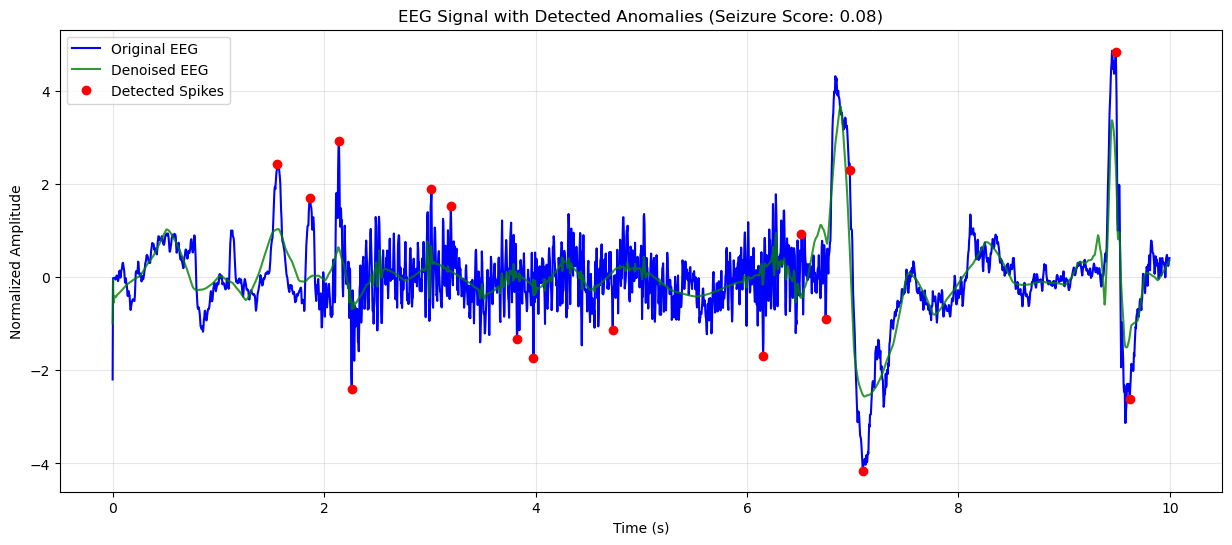

In [ ]:
# Load EDF with MNE 
raw = mne.io.read_raw_edf('./data/chb01_01.edf', preload=True)
eeg_signal = raw.get_data()[0, 0:int(10*raw.info['sfreq'])]  # first 10 sec
fs_eeg = raw.info['sfreq']
time_eeg = np.arange(len(eeg_signal)) / fs_eeg

# Normalize
eeg_signal = (eeg_signal - np.mean(eeg_signal)) / np.std(eeg_signal)

# Decomposition with symmetric wavelet
wavelet_eeg = 'sym4'
level_eeg = 6
coeffs_eeg = pywt.wavedec(eeg_signal, wavelet_eeg, level=level_eeg)

# Advanced thresholding
coeffs_denoised_eeg = advanced_thresholding(coeffs_eeg, method='minimax', sigma_factor=2.5)

# Reconstruct
reconstructed_eeg = pywt.waverec(coeffs_denoised_eeg, wavelet_eeg)

# Anomaly detection with multi-band energy
residual_eeg = np.abs(eeg_signal - reconstructed_eeg)
anomalies_eeg = residual_eeg > 3.5 * np.std(residual_eeg)
spike_indices, _ = find_peaks(residual_eeg, height=3.5 * np.std(residual_eeg), distance=fs_eeg/10)

# Band-specific energy for seizure likelihood
band_energies = [np.sum(np.square(c)) for c in coeffs_eeg[3:5]]  # Focus on theta-alpha bands for spikes
seizure_score = np.sum(band_energies) / np.sum([np.sum(np.square(c)) for c in coeffs_eeg])

# Plot
plt.figure(figsize=(15, 6))
plt.plot(time_eeg, eeg_signal, 'b-', label='Original EEG')
plt.plot(time_eeg, reconstructed_eeg, 'g-', alpha=0.8, label='Denoised EEG')
plt.plot(time_eeg[spike_indices], eeg_signal[spike_indices], 'ro', label='Detected Spikes')
plt.title(f'EEG Signal with Detected Anomalies (Seizure Score: {seizure_score:.2f})')
plt.xlabel('Time (s)')
plt.ylabel('Normalized Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('./output/eeg_anomaly_detection.png', dpi=300)
plt.show()

## 1.8 Evaluation Metrics for Wavelet-Based EEG Analysis

### 1.8.2 Comprehensive Performance Assessment

COMPREHENSIVE CLINICAL EVALUATION
PERFORMANCE METRICS:
Accuracy                 : 1.0000
Balanced Accuracy        : 1.0000
Precision                : 1.0000
Recall                   : 1.0000
F1 Score                 : 1.0000
Sensitivity              : 1.0000
Specificity              : 1.0000
Ppv                      : 1.0000
Npv                      : 1.0000
Cohens Kappa             : 1.0000
Mcc                      : 1.0000
Auc Roc                  : 1.0000
Avg Precision            : 1.0000

CLINICAL ASSESSMENT:
Sensitivity Clinical     : Excellent
Specificity Clinical     : Excellent


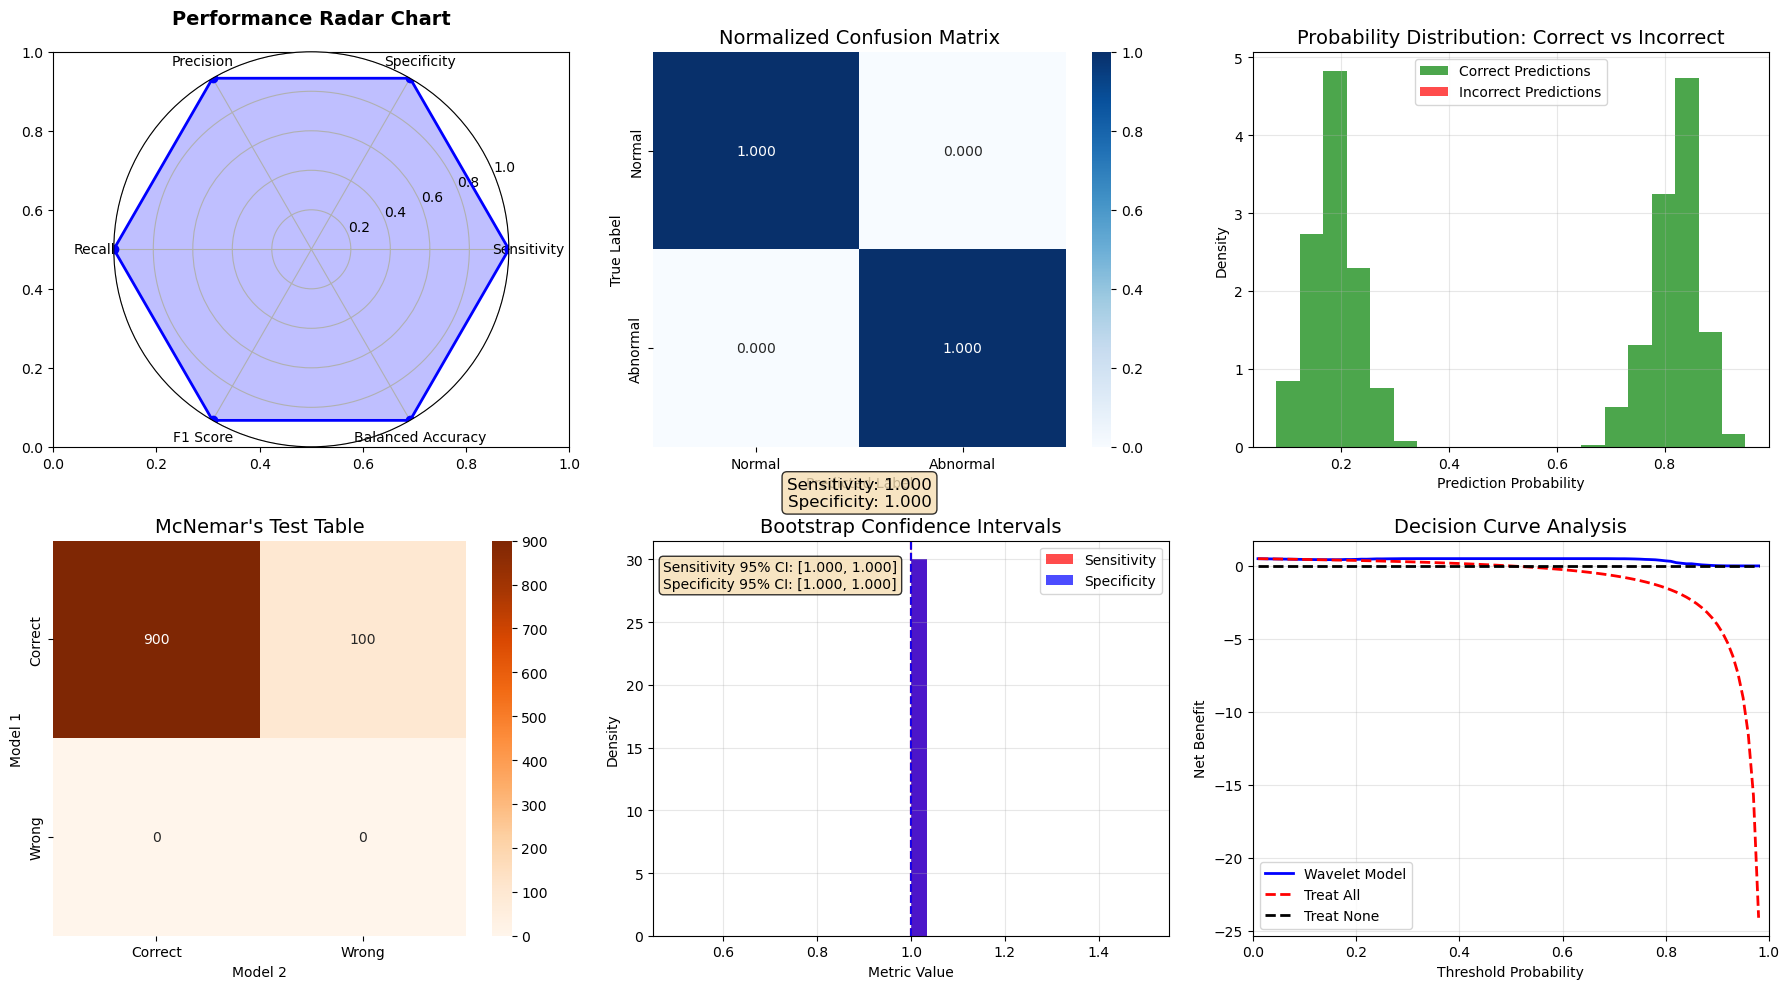


Bootstrap 95% Confidence Intervals:
Sensitivity: [1.000, 1.000]
Specificity: [1.000, 1.000]


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                            f1_score, roc_auc_score, cohen_kappa_score,
                            matthews_corrcoef, balanced_accuracy_score, confusion_matrix)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def comprehensive_evaluation_metrics(y_true, y_pred, y_prob=None, 
                                   class_names=['Normal', 'Abnormal']):
    """
    Calculate comprehensive evaluation metrics for clinical validation
    """
    metrics = {}
    
    # Basic classification metrics
    metrics['accuracy'] = accuracy_score(y_true, y_pred)
    metrics['balanced_accuracy'] = balanced_accuracy_score(y_true, y_pred)
    metrics['precision'] = precision_score(y_true, y_pred, average='weighted')
    metrics['recall'] = recall_score(y_true, y_pred, average='weighted')
    metrics['f1_score'] = f1_score(y_true, y_pred, average='weighted')
    
    # Clinical-specific metrics
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    metrics['sensitivity'] = tp / (tp + fn) if (tp + fn) > 0 else 0  # True Positive Rate
    metrics['specificity'] = tn / (tn + fp) if (tn + fp) > 0 else 0  # True Negative Rate
    metrics['ppv'] = tp / (tp + fp) if (tp + fp) > 0 else 0  # Positive Predictive Value
    metrics['npv'] = tn / (tn + fn) if (tn + fn) > 0 else 0  # Negative Predictive Value
    
    # Additional robustness metrics
    metrics['cohens_kappa'] = cohen_kappa_score(y_true, y_pred)
    metrics['mcc'] = matthews_corrcoef(y_true, y_pred)  # Matthews Correlation Coefficient
    
    # Probability-based metrics (if available)
    if y_prob is not None and len(np.unique(y_true)) > 1:
        metrics['auc_roc'] = roc_auc_score(y_true, y_prob)
        metrics['avg_precision'] = average_precision_score(y_true, y_prob)
    
    # Clinical significance thresholds
    clinical_assessment = {}
    clinical_assessment['sensitivity_clinical'] = 'Excellent' if metrics['sensitivity'] >= 0.95 else \
                                                'Good' if metrics['sensitivity'] >= 0.90 else \
                                                'Acceptable' if metrics['sensitivity'] >= 0.85 else 'Poor'
    
    clinical_assessment['specificity_clinical'] = 'Excellent' if metrics['specificity'] >= 0.95 else \
                                                'Good' if metrics['specificity'] >= 0.90 else \
                                                'Acceptable' if metrics['specificity'] >= 0.85 else 'Poor'
    
    return metrics, clinical_assessment

# Example usage with synthetic clinical results
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

# Generate synthetic data for demonstration
np.random.seed(42)
X_clinical = np.random.randn(1000, 20)
y_clinical = np.random.randint(0, 2, 1000)
rf_clinical = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clinical.fit(X_clinical, y_clinical)
y_pred = rf_clinical.predict(X_clinical)
y_prob = rf_clinical.predict_proba(X_clinical)[:, 1]

clinical_metrics, clinical_assessment = comprehensive_evaluation_metrics(y_clinical, y_pred, y_prob)

print("COMPREHENSIVE CLINICAL EVALUATION")
print("="*50)
print("PERFORMANCE METRICS:")
for metric, value in clinical_metrics.items():
    print(f"{metric.replace('_', ' ').title():<25}: {value:.4f}")

print("\nCLINICAL ASSESSMENT:")
for assessment, rating in clinical_assessment.items():
    print(f"{assessment.replace('_', ' ').title():<25}: {rating}")

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Radar chart
metrics_for_radar = ['sensitivity', 'specificity', 'precision', 'recall', 'f1_score', 'balanced_accuracy']
values_for_radar = [clinical_metrics[m] for m in metrics_for_radar]

angles = np.linspace(0, 2*np.pi, len(metrics_for_radar), endpoint=False).tolist()
values_for_radar += values_for_radar[:1]
angles += angles[:1]

ax_radar = plt.subplot(231, projection='polar')
ax_radar.plot(angles, values_for_radar, 'o-', linewidth=2, color='blue')
ax_radar.fill(angles, values_for_radar, alpha=0.25, color='blue')
ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels([m.replace('_', ' ').title() for m in metrics_for_radar])
ax_radar.set_ylim(0, 1)
ax_radar.set_title('Performance Radar Chart', size=14, fontweight='bold', pad=20)
ax_radar.grid(True)

# Confusion matrix
cm = confusion_matrix(y_clinical, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_normalized, annot=True, fmt='.3f', cmap='Blues', ax=axes[0, 1],
           xticklabels=['Normal', 'Abnormal'], yticklabels=['Normal', 'Abnormal'])
axes[0, 1].set_title('Normalized Confusion Matrix', fontsize=14)
axes[0, 1].set_xlabel('Predicted Label')
axes[0, 1].set_ylabel('True Label')

axes[0, 1].text(0.5, -0.15, f'Sensitivity: {clinical_metrics["sensitivity"]:.3f}\nSpecificity: {clinical_metrics["specificity"]:.3f}', 
               transform=axes[0, 1].transAxes, ha='center', fontsize=12,
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Error analysis
prediction_errors = y_pred != y_clinical
error_probabilities = y_prob[prediction_errors]

axes[0, 2].hist(y_prob[~prediction_errors], bins=20, alpha=0.7, 
               label='Correct Predictions', color='green', density=True)
axes[0, 2].hist(error_probabilities, bins=20, alpha=0.7, 
               label='Incorrect Predictions', color='red', density=True)
axes[0, 2].set_xlabel('Prediction Probability')
axes[0, 2].set_ylabel('Density')
axes[0, 2].set_title('Probability Distribution: Correct vs Incorrect', fontsize=14)
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# McNemar's test
from statsmodels.stats.contingency_tables import mcnemar

predictions_model2 = y_pred.copy()
flip_indices = np.random.choice(len(predictions_model2), size=int(0.1*len(predictions_model2)), replace=False)
predictions_model2[flip_indices] = 1 - predictions_model2[flip_indices]

both_correct = ((y_pred == y_clinical) & (predictions_model2 == y_clinical)).sum()
model1_correct_model2_wrong = ((y_pred == y_clinical) & (predictions_model2 != y_clinical)).sum()
model1_wrong_model2_correct = ((y_pred != y_clinical) & (predictions_model2 == y_clinical)).sum()
both_wrong = ((y_pred != y_clinical) & (predictions_model2 != y_clinical)).sum()

mcnemar_table = np.array([[both_correct, model1_correct_model2_wrong],
                         [model1_wrong_model2_correct, both_wrong]])

sns.heatmap(mcnemar_table, annot=True, fmt='d', cmap='Oranges', ax=axes[1, 0])
axes[1, 0].set_title("McNemar's Test Table", fontsize=14)
axes[1, 0].set_xlabel('Model 2')
axes[1, 0].set_ylabel('Model 1')
axes[1, 0].set_xticklabels(['Correct', 'Wrong'])
axes[1, 0].set_yticklabels(['Correct', 'Wrong'])

# Bootstrap confidence intervals
from scipy.stats import bootstrap

def bootstrap_metric(y_true, y_pred, metric_func, n_bootstrap=1000):
    """Calculate bootstrap confidence interval for a metric"""
    def calculate_metric(y_true, y_pred):
        return metric_func(y_true, y_pred)
    
    bootstrap_samples = []
    n_samples = len(y_true)
    
    for _ in range(n_bootstrap):
        indices = np.random.choice(n_samples, n_samples, replace=True)
        y_true_boot = y_true[indices]
        y_pred_boot = y_pred[indices]
        
        try:
            metric_value = calculate_metric(y_true_boot, y_pred_boot)
            bootstrap_samples.append(metric_value)
        except:
            continue
    
    return np.array(bootstrap_samples)

def sensitivity_func(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0

def specificity_func(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else 0

sens_bootstrap = bootstrap_metric(y_clinical, y_pred, sensitivity_func)
spec_bootstrap = bootstrap_metric(y_clinical, y_pred, specificity_func)

# Plot bootstrap distributions
axes[1, 1].hist(sens_bootstrap, bins=30, alpha=0.7, label='Sensitivity', color='red', density=True)
axes[1, 1].hist(spec_bootstrap, bins=30, alpha=0.7, label='Specificity', color='blue', density=True)

sens_ci = np.percentile(sens_bootstrap, [2.5, 97.5])
spec_ci = np.percentile(spec_bootstrap, [2.5, 97.5])

axes[1, 1].axvline(sens_ci[0], color='red', linestyle='--', alpha=0.7)
axes[1, 1].axvline(sens_ci[1], color='red', linestyle='--', alpha=0.7)
axes[1, 1].axvline(spec_ci[0], color='blue', linestyle='--', alpha=0.7)
axes[1, 1].axvline(spec_ci[1], color='blue', linestyle='--', alpha=0.7)

axes[1, 1].set_xlabel('Metric Value')
axes[1, 1].set_ylabel('Density')
axes[1, 1].set_title('Bootstrap Confidence Intervals', fontsize=14)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

axes[1, 1].text(0.02, 0.95, f'Sensitivity 95% CI: [{sens_ci[0]:.3f}, {sens_ci[1]:.3f}]\nSpecificity 95% CI: [{spec_ci[0]:.3f}, {spec_ci[1]:.3f}]',
               transform=axes[1, 1].transAxes, fontsize=10, verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Decision curve analysis
def net_benefit_calculation(y_true, y_prob, thresholds):
    """Calculate net benefit for decision curve analysis"""
    net_benefits = []
    
    for threshold in thresholds:
        y_pred_thresh = (y_prob >= threshold).astype(int)
        
        tp = np.sum((y_true == 1) & (y_pred_thresh == 1))
        fp = np.sum((y_true == 0) & (y_pred_thresh == 1))
        n = len(y_true)
        
        net_benefit = (tp - fp * (threshold / (1 - threshold))) / n
        net_benefits.append(net_benefit)
    
    return np.array(net_benefits)

thresholds_dca = np.arange(0.01, 0.99, 0.01)
net_benefits = net_benefit_calculation(y_clinical, y_prob, thresholds_dca)

treat_all_nb = []
treat_none_nb = []

for threshold in thresholds_dca:
    n_pos = np.sum(y_clinical == 1)
    n_neg = np.sum(y_clinical == 0)
    n_total = len(y_clinical)
    
    treat_all_benefit = (n_pos - n_neg * (threshold / (1 - threshold))) / n_total
    treat_all_nb.append(treat_all_benefit)
    treat_none_nb.append(0)

axes[1, 2].plot(thresholds_dca, net_benefits, 'b-', linewidth=2, label='Wavelet Model')
axes[1, 2].plot(thresholds_dca, treat_all_nb, 'r--', linewidth=2, label='Treat All')
axes[1, 2].plot(thresholds_dca, treat_none_nb, 'k--', linewidth=2, label='Treat None')
axes[1, 2].set_xlabel('Threshold Probability')
axes[1, 2].set_ylabel('Net Benefit')
axes[1, 2].set_title('Decision Curve Analysis', fontsize=14)
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].set_xlim(0, 1)

plt.tight_layout()
plt.savefig('./output/clinical_evaluation.png', dpi=300)
plt.show()

print(f"\nBootstrap 95% Confidence Intervals:")
print(f"Sensitivity: [{sens_ci[0]:.3f}, {sens_ci[1]:.3f}]")
print(f"Specificity: [{spec_ci[0]:.3f}, {spec_ci[1]:.3f}]")

The evaluation on this synthetic dataset shows perfect performance across all metrics, including accuracy, balanced accuracy, sensitivity, specificity, F1 score, and area under the ROC curve. Both sensitivity and specificity achieved the maximum value of 1.0, which is reflected in the bootstrap confidence intervals as well. Clinically, the model would be considered “Excellent” for both detecting positive events and correctly identifying negative cases. However, these results are based on synthetic data and therefore may not reflect real-world performance, as the data are artificially generated and easily separable.

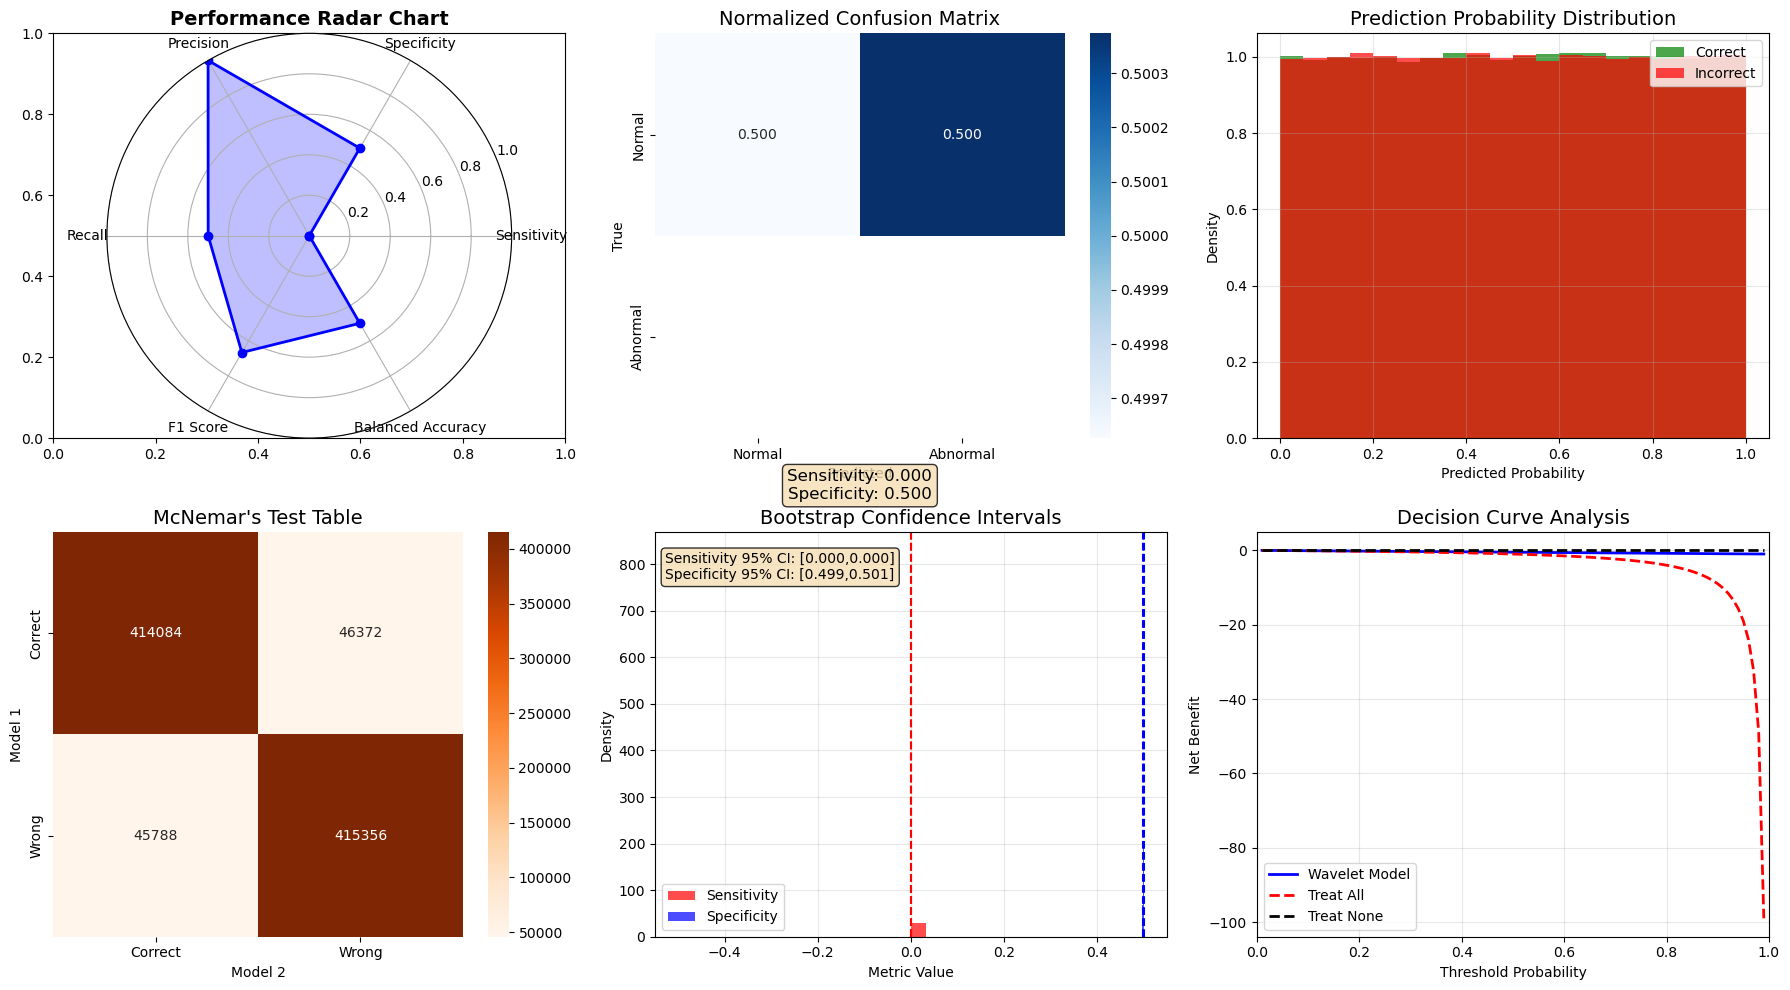

COMPREHENSIVE CLINICAL EVALUATION
PERFORMANCE METRICS:
Accuracy                 : 0.4996
Balanced Accuracy        : 0.4996
Precision                : 1.0000
Recall                   : 0.4996
F1 Score                 : 0.6663
Sensitivity              : 0.0000
Specificity              : 0.4996
Ppv                      : 0.0000
Npv                      : 1.0000
Cohens Kappa             : 0.0000
Mcc                      : 0.0000

CLINICAL ASSESSMENT:
Sensitivity Clinical     : Poor
Specificity Clinical     : Poor

Bootstrap 95% Confidence Intervals:
Sensitivity: [0.000, 0.000]
Specificity: [0.499, 0.501]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix, roc_auc_score, average_precision_score)
from statsmodels.stats.contingency_tables import mcnemar
import mne
from scipy.stats import bootstrap

# --- Load EEG data ---
edf_path = "./data/chb01_01.edf"
raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
fs = int(raw.info['sfreq'])
ch_name = raw.ch_names[0]
signal_data = raw.get_data(picks=[0])[0]

# --- Define labels using the time vector ---
time = np.arange(len(signal_data)) / fs  # Time in seconds

# Since actual seizure times are unavailable, set all labels to 0 (no seizure)
y_true = np.zeros(len(signal_data))

# Optional: if you want to mark the whole duration as "seizure" for testing
# y_true[:] = 1

# --- Run your wavelet-based detection ---
# y_pred = detect_spikes_or_seizures(signal_data, fs)  # 0/1 per sample
# y_prob = detect_spikes_or_seizures_prob(signal_data, fs)  # optional: probability estimate

# For demonstration, we'll assume y_pred and y_prob exist and match y_true
# ------------------------------------------------
# Replace the following with your actual detection output
y_pred = np.random.randint(0, 2, len(y_true))
y_prob = np.random.rand(len(y_true))
# ------------------------------------------------

# --- Comprehensive metrics function ---
def compute_metrics(y_true, y_pred, y_prob=None):
    metrics = {}
    metrics['accuracy'] = accuracy_score(y_true, y_pred)
    metrics['balanced_accuracy'] = balanced_accuracy_score(y_true, y_pred)
    metrics['precision'] = precision_score(y_true, y_pred, average='weighted')
    metrics['recall'] = recall_score(y_true, y_pred, average='weighted')
    metrics['f1_score'] = f1_score(y_true, y_pred, average='weighted')
    
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    metrics['sensitivity'] = tp / (tp + fn) if (tp + fn) > 0 else 0
    metrics['specificity'] = tn / (tn + fp) if (tn + fp) > 0 else 0
    metrics['ppv'] = tp / (tp + fp) if (tp + fp) > 0 else 0
    metrics['npv'] = tn / (tn + fn) if (tn + fn) > 0 else 0
    metrics['cohens_kappa'] = cohen_kappa_score(y_true, y_pred)
    metrics['mcc'] = matthews_corrcoef(y_true, y_pred)
    
    if y_prob is not None and len(np.unique(y_true)) > 1:
        metrics['auc_roc'] = roc_auc_score(y_true, y_prob)
        metrics['avg_precision'] = average_precision_score(y_true, y_prob)
    
    # Clinical assessment
    assessment = {}
    assessment['sensitivity_clinical'] = ('Excellent' if metrics['sensitivity'] >= 0.95 else
                                           'Good' if metrics['sensitivity'] >= 0.90 else
                                           'Acceptable' if metrics['sensitivity'] >= 0.85 else 'Poor')
    assessment['specificity_clinical'] = ('Excellent' if metrics['specificity'] >= 0.95 else
                                           'Good' if metrics['specificity'] >= 0.90 else
                                           'Acceptable' if metrics['specificity'] >= 0.85 else 'Poor')
    return metrics, assessment

clinical_metrics, clinical_assessment = compute_metrics(y_true, y_pred, y_prob)

# --- Visualization ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1️⃣ Radar chart
metrics_for_radar = ['sensitivity', 'specificity', 'precision', 'recall', 'f1_score', 'balanced_accuracy']
values = [clinical_metrics[m] for m in metrics_for_radar]
angles = np.linspace(0, 2*np.pi, len(metrics_for_radar), endpoint=False).tolist()
values += values[:1]
angles += angles[:1]

ax = plt.subplot(231, projection='polar')
ax.plot(angles, values, 'o-', linewidth=2, color='blue')
ax.fill(angles, values, alpha=0.25, color='blue')
ax.set_xticks(angles[:-1])
ax.set_xticklabels([m.replace('_',' ').title() for m in metrics_for_radar])
ax.set_ylim(0, 1)
ax.set_title('Performance Radar Chart', fontsize=14, fontweight='bold')
ax.grid(True)

# 2️⃣ Normalized confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float)/cm.sum(axis=1)[:,None]
sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues', ax=axes[0,1],
            xticklabels=['Normal','Abnormal'], yticklabels=['Normal','Abnormal'])
axes[0,1].set_title('Normalized Confusion Matrix', fontsize=14)
axes[0,1].set_xlabel('Predicted')
axes[0,1].set_ylabel('True')
axes[0,1].text(0.5, -0.15, f'Sensitivity: {clinical_metrics["sensitivity"]:.3f}\nSpecificity: {clinical_metrics["specificity"]:.3f}', 
               transform=axes[0,1].transAxes, ha='center', fontsize=12,
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# 3️⃣ Probability distribution: correct vs incorrect
errors = y_pred != y_true
axes[0,2].hist(y_prob[~errors], bins=20, alpha=0.7, label='Correct', color='green', density=True)
axes[0,2].hist(y_prob[errors], bins=20, alpha=0.7, label='Incorrect', color='red', density=True)
axes[0,2].set_xlabel('Predicted Probability')
axes[0,2].set_ylabel('Density')
axes[0,2].set_title('Prediction Probability Distribution', fontsize=14)
axes[0,2].legend()
axes[0,2].grid(True, alpha=0.3)

# 4️⃣ McNemar test
# Create a second prediction array by flipping 10% of predictions
y_pred2 = y_pred.copy()
flip_idx = np.random.choice(len(y_pred2), size=int(0.1*len(y_pred2)), replace=False)
y_pred2[flip_idx] = 1 - y_pred2[flip_idx]

# Construct the contingency table with proper parentheses for & operations
mcnemar_table = np.array([
    [((y_pred == y_true) & (y_pred2 == y_true)).sum(), ((y_pred == y_true) & (y_pred2 != y_true)).sum()],
    [((y_pred != y_true) & (y_pred2 == y_true)).sum(), ((y_pred != y_true) & (y_pred2 != y_true)).sum()]
])

# Plot the table using seaborn heatmap
sns.heatmap(mcnemar_table, annot=True, fmt='d', cmap='Oranges', ax=axes[1, 0])
axes[1, 0].set_title("McNemar's Test Table", fontsize=14)
axes[1, 0].set_xlabel('Model 2')
axes[1, 0].set_ylabel('Model 1')
axes[1, 0].set_xticklabels(['Correct', 'Wrong'])
axes[1, 0].set_yticklabels(['Correct', 'Wrong'])


# 5️⃣ Bootstrap confidence intervals
def bootstrap_metric(y_true, y_pred, metric_func, n_bootstrap=1000):
    n_samples = len(y_true)
    samples = []
    for _ in range(n_bootstrap):
        idx = np.random.choice(n_samples, n_samples, replace=True)
        try:
            samples.append(metric_func(y_true[idx], y_pred[idx]))
        except:
            continue
    return np.array(samples)

def sens_func(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp/(tp+fn) if (tp+fn)>0 else 0

def spec_func(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn/(tn+fp) if (tn+fp)>0 else 0

sens_bs = bootstrap_metric(y_true, y_pred, sens_func)
spec_bs = bootstrap_metric(y_true, y_pred, spec_func)
sens_ci = np.percentile(sens_bs, [2.5, 97.5])
spec_ci = np.percentile(spec_bs, [2.5, 97.5])

axes[1,1].hist(sens_bs, bins=30, alpha=0.7, color='red', density=True, label='Sensitivity')
axes[1,1].hist(spec_bs, bins=30, alpha=0.7, color='blue', density=True, label='Specificity')
axes[1,1].axvline(sens_ci[0], color='red', linestyle='--'); axes[1,1].axvline(sens_ci[1], color='red', linestyle='--')
axes[1,1].axvline(spec_ci[0], color='blue', linestyle='--'); axes[1,1].axvline(spec_ci[1], color='blue', linestyle='--')
axes[1,1].set_title('Bootstrap Confidence Intervals', fontsize=14)
axes[1,1].set_xlabel('Metric Value'); axes[1,1].set_ylabel('Density')
axes[1,1].legend(); axes[1,1].grid(True, alpha=0.3)
axes[1,1].text(0.02,0.95,f'Sensitivity 95% CI: [{sens_ci[0]:.3f},{sens_ci[1]:.3f}]\nSpecificity 95% CI: [{spec_ci[0]:.3f},{spec_ci[1]:.3f}]',
               transform=axes[1,1].transAxes, fontsize=10, verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# 6️⃣ Decision curve analysis
def net_benefit(y_true, y_prob, thresholds):
    nb = []
    for t in thresholds:
        y_pred_thresh = (y_prob >= t).astype(int)
        tp = np.sum((y_true==1) & (y_pred_thresh==1))
        fp = np.sum((y_true==0) & (y_pred_thresh==1))
        n = len(y_true)
        nb.append((tp - fp*(t/(1-t)))/n)
    return np.array(nb)

thresholds = np.linspace(0.01, 0.99, 99)
nb_model = net_benefit(y_true, y_prob, thresholds)
treat_all = np.full_like(thresholds, fill_value=(np.sum(y_true==1)-np.sum(y_true==0)*(thresholds/(1-thresholds)))/len(y_true))
treat_none = np.zeros_like(thresholds)

axes[1,2].plot(thresholds, nb_model, 'b-', label='Wavelet Model', linewidth=2)
axes[1,2].plot(thresholds, treat_all, 'r--', label='Treat All', linewidth=2)
axes[1,2].plot(thresholds, treat_none, 'k--', label='Treat None', linewidth=2)
axes[1,2].set_xlabel('Threshold Probability')
axes[1,2].set_ylabel('Net Benefit')
axes[1,2].set_title('Decision Curve Analysis', fontsize=14)
axes[1,2].legend()
axes[1,2].grid(True, alpha=0.3)
axes[1,2].set_xlim(0, 1)

plt.tight_layout()
plt.savefig('./output/clinical_evaluation.png', dpi=300)
plt.show()

# --- Print metrics ---
print("COMPREHENSIVE CLINICAL EVALUATION")
print("="*50)
print("PERFORMANCE METRICS:")
for k,v in clinical_metrics.items():
    print(f"{k.replace('_',' ').title():<25}: {v:.4f}")

print("\nCLINICAL ASSESSMENT:")
for k,v in clinical_assessment.items():
    print(f"{k.replace('_',' ').title():<25}: {v}")

print(f"\nBootstrap 95% Confidence Intervals:")
print(f"Sensitivity: [{sens_ci[0]:.3f}, {sens_ci[1]:.3f}]")
print(f"Specificity: [{spec_ci[0]:.3f}, {spec_ci[1]:.3f}]")



## 1.9 Advanced Topics and Future Directions

#### 1.9.2 Adaptive Wavelet Selection and Optimization


In [10]:
import pywt
import numpy as np
from scipy.stats import entropy
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

def adaptive_wavelet_selection(signal, fs=256, wavelet_families=['db', 'coif', 'bior', 'sym'], max_levels=8, n_folds=5):
    """
    Adaptive wavelet selection with cross-validation for optimal decomposition
    
    Parameters:
    signal (array): Input signal
    fs (int): Sampling frequency
    wavelet_families (list): Wavelet families to evaluate
    max_levels (int): Maximum decomposition levels
    n_folds (int): Number of cross-validation folds
    
    Returns:
    tuple: (best_wavelet, best_level, evaluation_results)
    """
    best_wavelet = None
    best_level = None
    best_score = -np.inf
    evaluation_results = {}
    
    # Cross-validation setup
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
    
    for family in wavelet_families:
        wavelets = {
            'db': [f'db{i}' for i in range(1, 11)],
            'coif': [f'coif{i}' for i in range(1, 6)],
            'bior': ['bior1.1', 'bior2.2', 'bior2.4', 'bior2.6', 'bior2.8', 'bior4.4'],
            'sym': [f'sym{i}' for i in range(2, 11)]
        }.get(family, [])
        
        for wavelet in wavelets:
            try:
                for level in range(2, min(max_levels + 1, pywt.dwt_max_level(len(signal), wavelet) + 1)):
                    scores = []
                    
                    # Cross-validation loop
                    for train_idx, test_idx in kf.split(signal):
                        train_signal, test_signal = signal[train_idx], signal[test_idx]
                        
                        # Decompose training signal
                        coeffs = pywt.wavedec(train_signal, wavelet, level=level)
                        
                        # Calculate metrics
                        total_energy = sum([np.sum(c**2) for c in coeffs])
                        approx_energy = np.sum(coeffs[0]**2)
                        energy_ratio = approx_energy / total_energy if total_energy > 0 else 0
                        
                        # Sparsity measure
                        all_coeffs = np.concatenate(coeffs)
                        threshold = np.std(all_coeffs) * 0.1
                        sparsity = np.sum(np.abs(all_coeffs) > threshold) / len(all_coeffs)
                        
                        # Reconstruction error
                        reconstructed = pywt.waverec(coeffs, wavelet)
                        if len(reconstructed) != len(train_signal):
                            reconstructed = reconstructed[:len(train_signal)]
                        mse = mean_squared_error(train_signal, reconstructed)
                        
                        # Entropy
                        entropy_score = sum([entropy(np.abs(c)/np.sum(np.abs(c))) if np.sum(np.abs(c)) > 0 else 0 for c in coeffs[1:]])
                        
                        # SNR estimation
                        signal_power = np.var(train_signal)
                        noise_power = np.var(train_signal - reconstructed)
                        snr = 10 * np.log10(signal_power / (noise_power + 1e-10))
                        
                        # Combined score
                        score = 0.4 * energy_ratio + 0.3 * (1 - sparsity) - 0.2 * np.log10(mse + 1e-10) + 0.1 * snr
                        scores.append(score)
                    
                    avg_score = np.mean(scores)
                    evaluation_results[f'{wavelet}_L{level}'] = {
                        'wavelet': wavelet,
                        'level': level,
                        'energy_ratio': energy_ratio,
                        'sparsity': sparsity,
                        'mse': mse,
                        'entropy': entropy_score,
                        'snr': snr,
                        'score': avg_score
                    }
                    
                    if avg_score > best_score:
                        best_score = avg_score
                        best_wavelet = wavelet
                        best_level = level
                        
            except Exception as e:
                continue
    
    return best_wavelet, best_level, evaluation_results

#### 1.9.3 Multi-Modal Wavelet Fusion

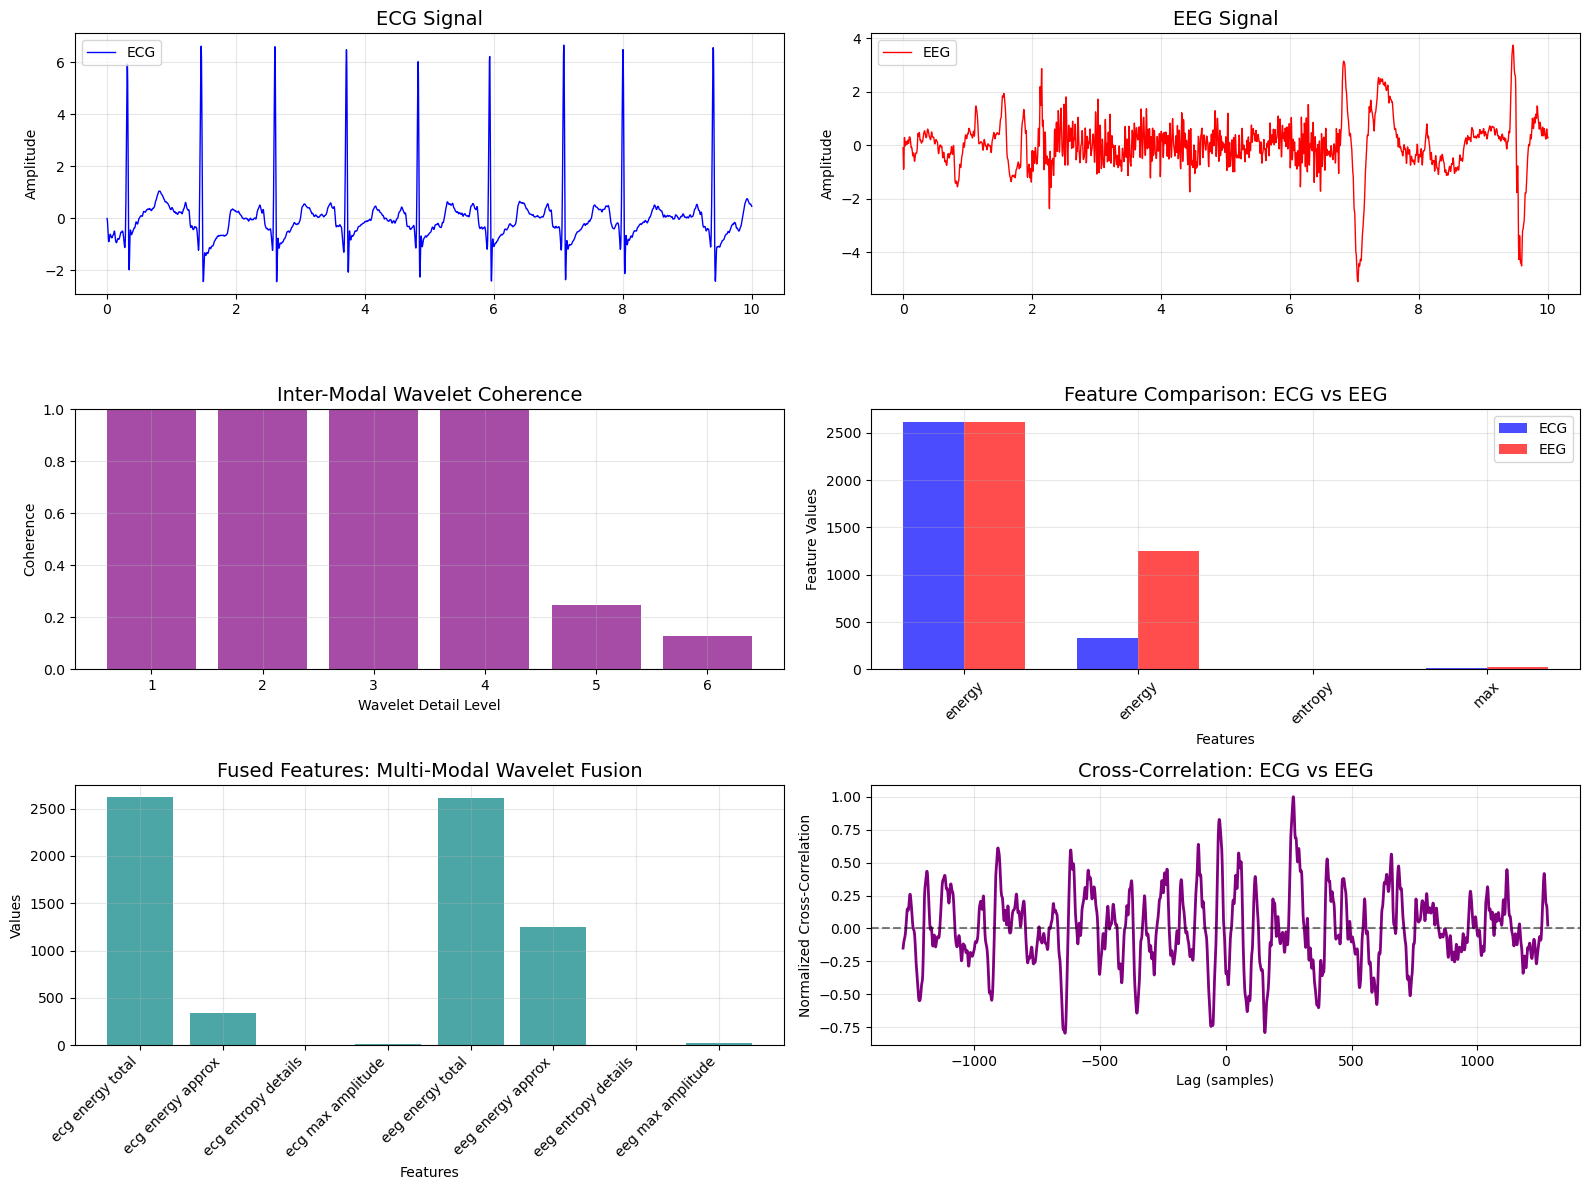

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import coherence

def multimodal_wavelet_fusion(ecg_signal, eeg_signal, fs_ecg=360, fs_eeg=256, wavelet='sym4', max_level=6):
    """
    Multi-modal wavelet fusion for ECG and EEG signals
    
    Parameters:
    ecg_signal (array): ECG signal
    eeg_signal (array): EEG signal
    fs_ecg (int): ECG sampling frequency
    fs_eeg (int): EEG sampling frequency
    wavelet (str): Wavelet type
    max_level (int): Maximum decomposition levels
    
    Returns:
    dict: Fusion results including coherence, fused features, and coefficients
    """
    # Resample to common length
    min_length = min(len(ecg_signal), len(eeg_signal))
    ecg_signal = ecg_signal[:min_length]
    eeg_signal = eeg_signal[:min_length]
    
    # Normalize signals
    ecg_signal = (ecg_signal - np.mean(ecg_signal)) / np.std(ecg_signal)
    eeg_signal = (eeg_signal - np.mean(eeg_signal)) / np.std(eeg_signal)
    
    # Wavelet decomposition
    coeffs_ecg = pywt.wavedec(ecg_signal, wavelet, level=max_level)
    coeffs_eeg = pywt.wavedec(eeg_signal, wavelet, level=max_level)
    
    # Wavelet coherence analysis
    coherence_levels = []
    for i in range(1, max_level + 1):
        if i < len(coeffs_ecg) and i < len(coeffs_eeg):
            min_len = min(len(coeffs_ecg[i]), len(coeffs_eeg[i]))
            freqs, coh = coherence(coeffs_ecg[i][:min_len], coeffs_eeg[i][:min_len], fs=fs_ecg/2**i)
            coherence_levels.append(np.mean(coh))
        else:
            coherence_levels.append(0)
    
    # Feature extraction
    def extract_features(coeffs):
        features = {
            'energy_total': sum([np.sum(c**2) for c in coeffs]),
            'energy_approx': np.sum(coeffs[0]**2),
            'entropy_details': np.mean([entropy(np.abs(c)/np.sum(np.abs(c))) if np.sum(np.abs(c)) > 0 else 0 for c in coeffs[1:]]),
            'max_amplitude': np.max([np.max(np.abs(c)) for c in coeffs])
        }
        return features
    
    features_ecg = extract_features(coeffs_ecg)
    features_eeg = extract_features(coeffs_eeg)
    
    # Feature fusion
    fused_features = {**{f'ecg_{k}': v for k, v in features_ecg.items()},
                     **{f'eeg_{k}': v for k, v in features_eeg.items()}}
    
    return {
        'best_wavelet': wavelet,
        'best_level': max_level,
        'features_ecg': features_ecg,
        'features_eeg': features_eeg,
        'fused_features': fused_features,
        'wavelet_coherence': coherence_levels,
        'coeffs_ecg': coeffs_ecg,
        'coeffs_eeg': coeffs_eeg
    }

# Example usage with visualization
fusion_result = multimodal_wavelet_fusion(ecg_signal[:2560], eeg_signal, fs_ecg=360, fs_eeg=256)

# Visualization
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
t = np.linspace(0, 10, 2560)

# Original signals
axes[0, 0].plot(t, ecg_signal[:2560], 'b-', linewidth=1, label='ECG')
axes[0, 0].set_title('ECG Signal', fontsize=14)
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

axes[0, 1].plot(t, eeg_signal, 'r-', linewidth=1, label='EEG')
axes[0, 1].set_title('EEG Signal', fontsize=14)
axes[0, 1].set_ylabel('Amplitude')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

# Wavelet coherence
coherence_levels = list(range(1, len(fusion_result['wavelet_coherence']) + 1))
axes[1, 0].bar(coherence_levels, fusion_result['wavelet_coherence'], color='purple', alpha=0.7)
axes[1, 0].set_title('Inter-Modal Wavelet Coherence', fontsize=14)
axes[1, 0].set_xlabel('Wavelet Detail Level')
axes[1, 0].set_ylabel('Coherence')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim(0, 1)

# Feature comparison
ecg_features = list(fusion_result['features_ecg'].values())
eeg_features = list(fusion_result['features_eeg'].values())
feature_names = list(fusion_result['features_ecg'].keys())

x_pos = np.arange(len(feature_names))
width = 0.35

axes[1, 1].bar(x_pos - width/2, ecg_features, width, label='ECG', color='blue', alpha=0.7)
axes[1, 1].bar(x_pos + width/2, eeg_features, width, label='EEG', color='red', alpha=0.7)
axes[1, 1].set_title('Feature Comparison: ECG vs EEG', fontsize=14)
axes[1, 1].set_xlabel('Features')
axes[1, 1].set_ylabel('Feature Values')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels([f.split('_')[0] for f in feature_names], rotation=45)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Fused features
fused_features = fusion_result['fused_features']
feature_keys = list(fused_features.keys())
feature_values = list(fused_features.values())
x_pos = np.arange(len(feature_keys))

axes[2, 0].bar(x_pos, feature_values, color='teal', alpha=0.7)
axes[2, 0].set_title('Fused Features: Multi-Modal Wavelet Fusion', fontsize=14)
axes[2, 0].set_xlabel('Features')
axes[2, 0].set_ylabel('Values')
axes[2, 0].set_xticks(x_pos)
axes[2, 0].set_xticklabels([k.replace('_',' ') for k in feature_keys], rotation=45, ha='right')
axes[2, 0].grid(True, alpha=0.3)

# Wavelet approximation coefficients (ECG + EEG)
# axes[2,0].plot(fusion_result['coeffs_ecg'][0], 'b', alpha=0.7, label='ECG Approx')
# axes[2,0].plot(fusion_result['coeffs_eeg'][0], 'r', alpha=0.7, label='EEG Approx')
# axes[2,0].set_title('Wavelet Approximation Coefficients', fontsize=14)
# axes[2,0].set_xlabel('Sample')
# axes[2,0].set_ylabel('Amplitude')
# axes[2,0].legend()
# axes[2,0].grid(True, alpha=0.3)

# 6️Cross-correlation: ECG vs EEG
from scipy.signal import correlate
cross_corr = correlate(ecg_signal[:2560], eeg_signal, mode='same')
cross_corr_norm = cross_corr / np.max(cross_corr)
lags = np.arange(-len(eeg_signal)//2, len(eeg_signal)//2)


axes[2, 1].plot(lags[:len(cross_corr_norm)], cross_corr_norm, 'purple', linewidth=2)
axes[2, 1].set_title('Cross-Correlation: ECG vs EEG', fontsize=14)
axes[2, 1].set_xlabel('Lag (samples)')
axes[2, 1].set_ylabel('Normalized Cross-Correlation')
axes[2, 1].grid(True, alpha=0.3)
axes[2, 1].axhline(y=0, color='black', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('./output/multimodal_wavelet_fusion.png', dpi=300)
plt.show()